# 08 — Regularization Experiments: Lasso, Ridge & Elastic Net

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor: Scaling is mandatory for regularized logistic regression!
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Fitting L1, L2 and Elastic Net across C Values


In [3]:
# Transform training and test matrices
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
results_list = []
coef_l1_history = []
coef_l2_history = []

for c in c_values:
    # 1. L1 (Lasso) using saga solver
    lr_l1 = LogisticRegression(penalty='l1', C=c, solver='saga', max_iter=2000, random_state=RANDOM_STATE)
    lr_l1.fit(X_train_trans, y_train)
    y_prob_l1 = lr_l1.predict_proba(X_test_trans)[:, 1]
    y_pred_l1 = lr_l1.predict(X_test_trans)
    
    n_zeros_l1 = np.sum(lr_l1.coef_[0] == 0.0)
    n_active_l1 = np.sum(lr_l1.coef_[0] != 0.0)
    coef_l1_history.append(lr_l1.coef_[0])
    
    results_list.append({
        'Penalty': 'L1 (Lasso)',
        'C': c,
        'Zero_Coefficients': n_zeros_l1,
        'Active_Features': n_active_l1,
        'Test_Accuracy': accuracy_score(y_test, y_pred_l1),
        'Test_Recall': recall_score(y_test, y_pred_l1),
        'Test_F1': f1_score(y_test, y_pred_l1),
        'Test_ROC_AUC': roc_auc_score(y_test, y_prob_l1)
    })
    
    # 2. L2 (Ridge) using lbfgs solver
    lr_l2 = LogisticRegression(penalty='l2', C=c, solver='lbfgs', max_iter=2000, random_state=RANDOM_STATE)
    lr_l2.fit(X_train_trans, y_train)
    y_prob_l2 = lr_l2.predict_proba(X_test_trans)[:, 1]
    y_pred_l2 = lr_l2.predict(X_test_trans)
    
    n_zeros_l2 = np.sum(lr_l2.coef_[0] == 0.0)
    n_active_l2 = np.sum(lr_l2.coef_[0] != 0.0)
    coef_l2_history.append(lr_l2.coef_[0])
    
    results_list.append({
        'Penalty': 'L2 (Ridge)',
        'C': c,
        'Zero_Coefficients': n_zeros_l2,
        'Active_Features': n_active_l2,
        'Test_Accuracy': accuracy_score(y_test, y_pred_l2),
        'Test_Recall': recall_score(y_test, y_pred_l2),
        'Test_F1': f1_score(y_test, y_pred_l2),
        'Test_ROC_AUC': roc_auc_score(y_test, y_prob_l2)
    })

df_reg_results = pd.DataFrame(results_list)
df_reg_results.to_csv('../../outputs/tables/lasso_ridge_c_experiment.csv', index=False)

print('=== Regularization Experiment Results across C values ===')
display(df_reg_results)

=== Regularization Experiment Results across C values ===


,Penalty,C,Zero_Coefficients,Active_Features,Test_Accuracy,Test_Recall,Test_F1,Test_ROC_AUC
0,L1 (Lasso),0.001,56,1,0.8020,0.000000,0.000000,0.810530
1,L2 (Ridge),0.001,0,57,0.8400,0.265152,0.396226,0.864901
2,L1 (Lasso),0.010,46,11,0.8445,0.361111,0.479062,0.864845
3,L2 (Ridge),0.010,0,57,0.8530,0.424242,0.533333,0.881978
4,L1 (Lasso),0.100,28,29,0.8650,0.502525,0.595808,0.888152
5,L2 (Ridge),0.100,0,57,0.8640,0.510101,0.597633,0.889185
6,L1 (Lasso),1.000,2,55,0.8665,0.522727,0.607930,0.890240
7,L2 (Ridge),1.000,0,57,0.8650,0.520202,0.604106,0.890460
8,L1 (Lasso),10.000,0,57,0.8645,0.520202,0.603221,0.890662
9,L2 (Ridge),10.000,0,57,0.8640,0.517677,0.601173,0.890583


## 4. Visualising Sparsity & Regularization Paths


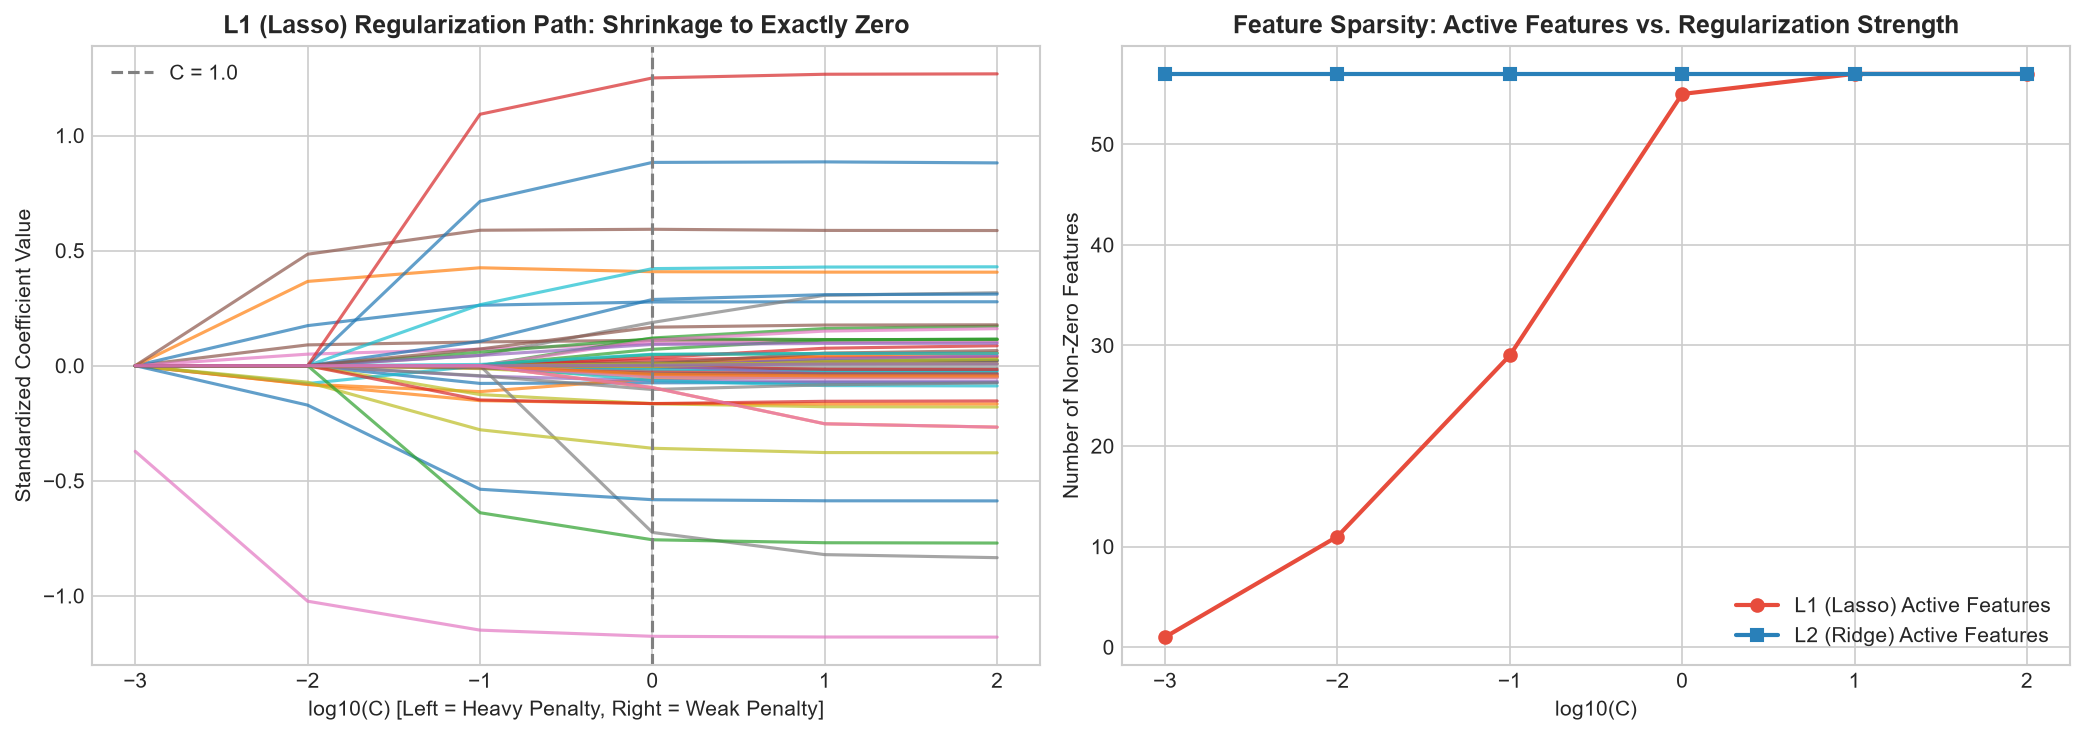

In [4]:
# Extract feature names
feature_names = (
    numeric_cols +
    list(preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot L1 coefficient paths
coef_l1_matrix = np.array(coef_l1_history)
for j in range(len(feature_names)):
    axes[0].plot(np.log10(c_values), coef_l1_matrix[:, j], alpha=0.7)
axes[0].set_title('L1 (Lasso) Regularization Path: Shrinkage to Exactly Zero', weight='bold')
axes[0].set_xlabel('log10(C) [Left = Heavy Penalty, Right = Weak Penalty]')
axes[0].set_ylabel('Standardized Coefficient Value')
axes[0].axvline(0, color='gray', linestyle='--', label='C = 1.0')
axes[0].legend()

# Plot Active Features vs C
l1_df = df_reg_results[df_reg_results['Penalty'] == 'L1 (Lasso)']
l2_df = df_reg_results[df_reg_results['Penalty'] == 'L2 (Ridge)']

axes[1].plot(np.log10(l1_df['C']), l1_df['Active_Features'], marker='o', color='#e74c3c', lw=2, label='L1 (Lasso) Active Features')
axes[1].plot(np.log10(l2_df['C']), l2_df['Active_Features'], marker='s', color='#2980b9', lw=2, label='L2 (Ridge) Active Features')
axes[1].set_title('Feature Sparsity: Active Features vs. Regularization Strength', weight='bold')
axes[1].set_xlabel('log10(C)')
axes[1].set_ylabel('Number of Non-Zero Features')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_regularization_paths.png', dpi=150)
plt.show()

## 5. Sparse Feature Selection: The Core Credit Risk Signal


In [5]:
# Inspect the model coefficients at C=0.01 (Sparse model)
sparse_lr = LogisticRegression(penalty='l1', C=0.01, solver='saga', max_iter=2000, random_state=RANDOM_STATE)
sparse_lr.fit(X_train_trans, y_train)

df_sparse_coef = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient_at_C_0_01': sparse_lr.coef_[0]
}).query('Coefficient_at_C_0_01 != 0.0').sort_values('Coefficient_at_C_0_01', key=abs, ascending=False).reset_index(drop=True)

print('=== Top Surviving Features Selected by Lasso at Heavy Penalty (C=0.01) ===')
display(df_sparse_coef)

=== Top Surviving Features Selected by Lasso at Heavy Penalty (C=0.01) ===


,Feature,Coefficient_at_C_0_01
0,Credit_Score,-1.023370
1,Debt_to_Income,0.484366
2,Late_Payments_2Y,0.366139
3,Credit_Utilization_Pct,0.173977
4,Salary_Account_With_Bank,-0.171399
5,Interest_Rate_Pct,0.090339
6,Log_Savings_Balance,-0.081683
7,Years_Employed,-0.080844
8,Log_Annual_Income,-0.077670
9,Employment_Type_Salaried,-0.071730
